# Lab 5 : Mixture Models

Welcome to the advanced Machine Learning Course.

The objective of this lab session is to [...].

Please put **"ML - MDS - TD5"** in the mail subject or I might lose your work (which means 0) and send it to ludovic.trautmann@inria.fr

Please label your notebook **"L5_familyname1_familyname2.ipynb"**.

Make sure to put comments in your code. **Raw numerical results or plots without comments will have almost no value in the grading. Please make sure to comment yout results.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
sns.set_context('poster')
sns.set_color_codes()
plot_kwds = {'alpha' : 0.25, 's' : 80, 'linewidths':0}

## GMM

A Gaussian mixture model is a probabilistic model that assumes all the data points are generated from a mixture of a finite number of Gaussian distributions with unknown parameters. After estimation of those parameters we get an estimation of the distribution of our data. For the clustering task, one can think of mixture models as generalizing k-means clustering to incorporate information about the covariance structure of the data as well as the centers of the latent Gaussians. 



Fill in the following class to implement a multivariate GMM:



In [ ]:
from sklearn.cluster import KMeans

class my_GMM():
    
    def __init__(self, k, debug=False, n_iter=1000):
        '''
        Parameters:
        k: integer
            number of components
        
        Attributes:
        
        alpha_: np.array
            proportion of components
        mu_: np.array
            array containing means
        Sigma_: np.array
            array containing covariance matrix
        cond_prob_: (n, K) np.array
            conditional probabilities for all data points 
        labels_: (n, ) np.array
            labels for data points
        '''
        self.k = k
        self.alpha_ = None
        self.mu_ = None
        self.Sigma_ = None
        self.cond_prob_ = None
        self.labels_ = None
        self.n_iter = n_iter
        self.debug = debug
        self.labels_per_iter = []

    def compute_condition_prob_matrix(self, X, alpha, mu, Sigma):
        '''Compute the conditional probability matrix 
        shape: (n, K)
        '''
        # This is the E-step of the EM algorithm
        n,p = X.shape
        conditional_probs = np.zeros((n,self.k))
        for j in range(self.k):
            rij = alpha[j]
            inv = np.linalg.pinv(Sigma[j])
            det = np.linalg.det(Sigma[j])
            scale = (2*np.pi)**(-p/2)/det**(1/2)
            # (n,p) * (p,p) * (p, n) = (n,n)
            diff = X-mu[j]
            new = rij *scale*np.exp(-0.5*np.einsum('np, pq, nq->n', diff, inv, diff)) 
            conditional_probs[:, j] = new 

        # We need still to scale to make the sik sum to 1, at i fixed.
        for i in range(n):
            conditional_probs[i,:] /= np.sum(conditional_probs[i,:])

        return conditional_probs
    def fit(self, X):
        """ Find the parameters
        that better fit the data
        
        Parameters:
        -----------
        X: (n, p) np.array
            Data matrix
        
        Returns:
        -----
        self
        """

        
        
        # TODO:
        # initialize the parameters
        # apply sklearn kmeans or randomly initialize them
        n,p = X.shape
        cls = KMeans(n_clusters=self.k)
        cls.fit(X)
        labels = cls.labels_
        centers = cls.cluster_centers_
        self.mu_ = centers
        self.Sigma_ = np.array([np.eye(X.shape[1]) for _ in range(self.k)])
        self.alpha_ = np.zeros(self.k)
        _, count = np.unique(labels, return_counts=True)
        self.alpha_ = count/n
        if self.debug:
            print(f"Initial parameters: alpha={self.alpha_}, mu={self.mu_}, Sigma={self.Sigma_}")

        iter = 0
        while iter < self.n_iter:
            iter += 1
            self.cond_prob_ = self.compute_condition_prob_matrix(X, self.alpha_, self.mu_, self.Sigma_)
            N = np.sum(self.cond_prob_, axis=0)
            if self.debug:
                print(f"{N.shape=}")
            self.alpha_ = N/n # Update mixture weights
            self.mu_ = np.einsum('nk, np -> kp', self.cond_prob_, X)*1/N[:, None] # Update means
            if self.debug:
                print(f"{self.mu_.shape=}")
            diff = X[:, None, :] - self.mu_[None, :, :]
            self.Sigma_ = np.einsum('nk, nkl, nkm -> klm', self.cond_prob_, diff, diff)*1/N[:, None, None] # Update covariance matrices    
            if self.debug:
                print(f"{self.Sigma_.shape=}")
            self.labels_per_iter.append(np.argmax(self.cond_prob_, axis=1))


        self.labels_ = np.argmax(self.cond_prob_, axis=1)
        

        # Update labels_
        
        # Return self
        
    def predict(self, X):
        """ Predict labels for X
        
        Parameters:
        -----------
        X: (n, p) np.array
            New data matrix
        
        Returns:
        -----
        label assigment        
        """
        # TODO
        self.cond_prob_ = self.compute_condition_prob_matrix(X, self.alpha_, self.mu_, self.Sigma_)
        self.labels_ = np.argmax(self.cond_prob_, axis=1)
        return self.labels_
        
    def compute_proba(self, X):
        """ Compute probability vector for X
        
        Parameters:
        -----------
        X: (n, p) np.array
            New data matrix
        
        Returns:
        -----
        proba: (n, k) np.array        
        """
        # TODO
        self.cond_prob_ = self.compute_condition_prob_matrix(X, self.alpha_, self.mu_, self.Sigma_)
        return self.cond_prob_

    def generate_gif(self, X, filename='gmm.gif', fps=2, n_frames=100):
        from matplotlib import animation

        # Keep only n_frames evenly spaced iterations to speed up the generation
        frames = np.linspace(0, len(self.labels_per_iter) - 1, n_frames, dtype=int)

        fig, ax = plt.subplots(figsize=(8, 6))
        scat = ax.scatter(X[:, 0], X[:, 1], c=self.labels_per_iter[0], cmap='viridis', s=30, alpha=0.5, vmin=0, vmax=self.k - 1)

        def update(i):
            scat.set_array(self.labels_per_iter[i])
            ax.set_title(f'GMM iteration {i + 1}')
            return scat,

        anim = animation.FuncAnimation(fig, update, frames=frames, blit=False)
        anim.save(filename, writer=animation.PillowWriter(fps=fps))
        plt.close(fig)
        return filename


Generate your own mixture of Gaussian distributions to test the model, choose parameters so that GMM performs better than K-Means on it. Use `np.random.multivariate_normal`. 

Plot data with colors representing predicted labels and shapes representing real labels.

## Data Generation

In [37]:
def generate_gmm_data(
    K=3,
    n_per_cluster=100,
    distance=5,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    means = []
    while len(means) < K:
        candidate = rng.uniform(-distance, distance, size=2)
        means.append(candidate)
    means = np.array(means)

    covariances = []
    for k in range(K):
        var1 = rng.uniform(1.0, 4.0)
        var2 = rng.uniform(0.2, 1.0)
        theta = rng.uniform(0, np.pi)
        rotation = np.array([
            [np.cos(theta), -np.sin(theta)],
            [np.sin(theta),  np.cos(theta)]
        ])

        cov = rotation @ np.diag([var1, var2]) @ rotation.T
        covariances.append(cov)

    covariances = np.array(covariances)

    # Generate observations
    X_list = []
    y_list = []

    for k in range(K):
        X_k = rng.multivariate_normal(
            mean=means[k],
            cov=covariances[k],
            size=n_per_cluster
        )

        X_list.append(X_k)
        y_list.append(np.full(n_per_cluster, k))

    X = np.vstack(X_list)
    y = np.concatenate(y_list)

    # Shuffle the data to avoid any ordering effects
    indices = rng.permutation(len(X))
    X = X[indices]
    y = y[indices]

    return X, y, means, covariances


K = 5
X, y, means, covariances = generate_gmm_data(K=K, n_per_cluster=100)
X_easy, y_easy, means_easy, covariances_easy = generate_gmm_data(K=3, n_per_cluster=100, distance=5)


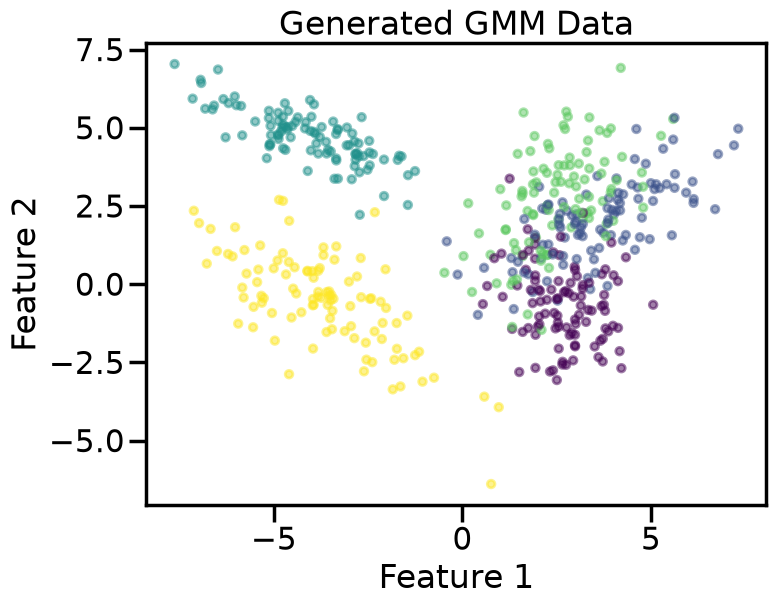

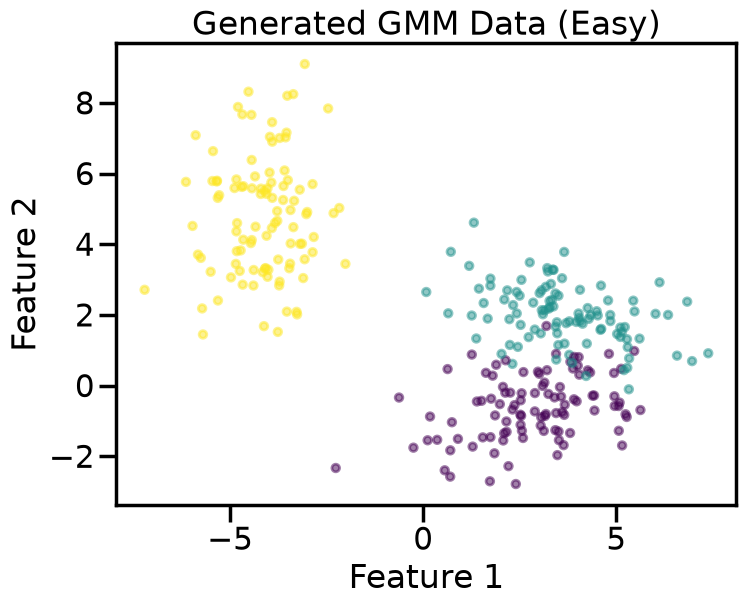

In [38]:
def plot_gaussian_mixtures(X,y,title):
    plt.figure(figsize=(8, 6))
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=30, alpha=0.5)
    plt.title(title)
    plt.xlabel('Feature 1')
    plt.ylabel('Feature 2')
    plt.show()
plot_gaussian_mixtures(X, y, title='Generated GMM Data')
plot_gaussian_mixtures(X_easy, y_easy, title='Generated GMM Data (Easy)')


**Comments:** On the normal dataset, some clusters are very close, even superposed (the green, dark blue and purple ones). The model will probably have a hard time distinguishing them. On the other hand, clusters in the easy dataset are more distinct and should be separated more easily. 

## Initialization of the model

In [39]:
# Initialize and fit the GMM model

my_gmm = my_GMM(k = K)
my_gmm.fit(X=X)
my_labels = my_gmm.labels_

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)

my_gmm_easy = my_GMM(k = 3)
my_gmm_easy.fit(X=X_easy)

kmeans_easy = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_easy_labels = kmeans_easy.fit_predict(X_easy)


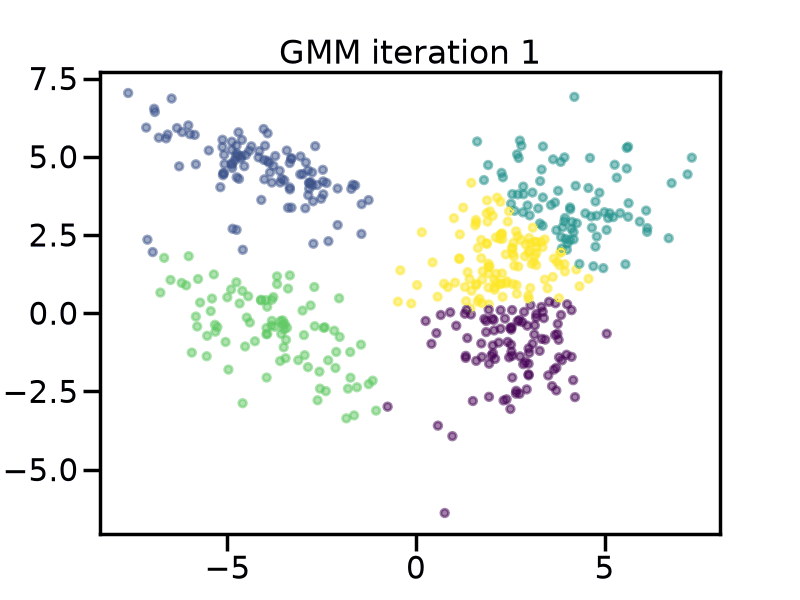

In [51]:

from IPython.display import Image
Image(filename=my_gmm.generate_gif(X))

**Comments:** Here we see the evolution of the labels during the fitting stage. The convergence happens quite fast. It makes sense, since the algorithm was initialised with K-means (already a good clustering from the beginning, but we try to improve it). 

## Results plot

In [45]:
def plot_predictions(X, y, my_labels, kmeans_labels, K):
    markers = ['o', '*', '^', 's', 'D', 'P', 'X', 'v']

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    for k in range(K):
        for j in range(K):
            mask = (y == k) & (my_labels == j)

            axes[0].scatter(
                X[mask, 0],
                X[mask, 1],
                c=[plt.cm.viridis(j / max(K-1, 1))],
                marker=markers[k],
                s=30,
                alpha=0.5,
                label=f'Réel {k}, prédit {j}'
            )

    axes[0].set_title("GMM prediction")
    axes[0].axis('equal')

    for k in range(K):
        for j in range(K):
            mask = (y == k) & (kmeans_labels == j)

            axes[1].scatter(
                X[mask, 0],
                X[mask, 1],
                c=[plt.cm.viridis(j / max(K-1, 1))],
                marker=markers[k],
                s=30,
                alpha=0.5,
                label=f'Réel {k}, prédit {j}'
            )

    axes[1].set_title("KMean prediction")
    axes[1].axis('equal')

    plt.tight_layout()
    plt.show()


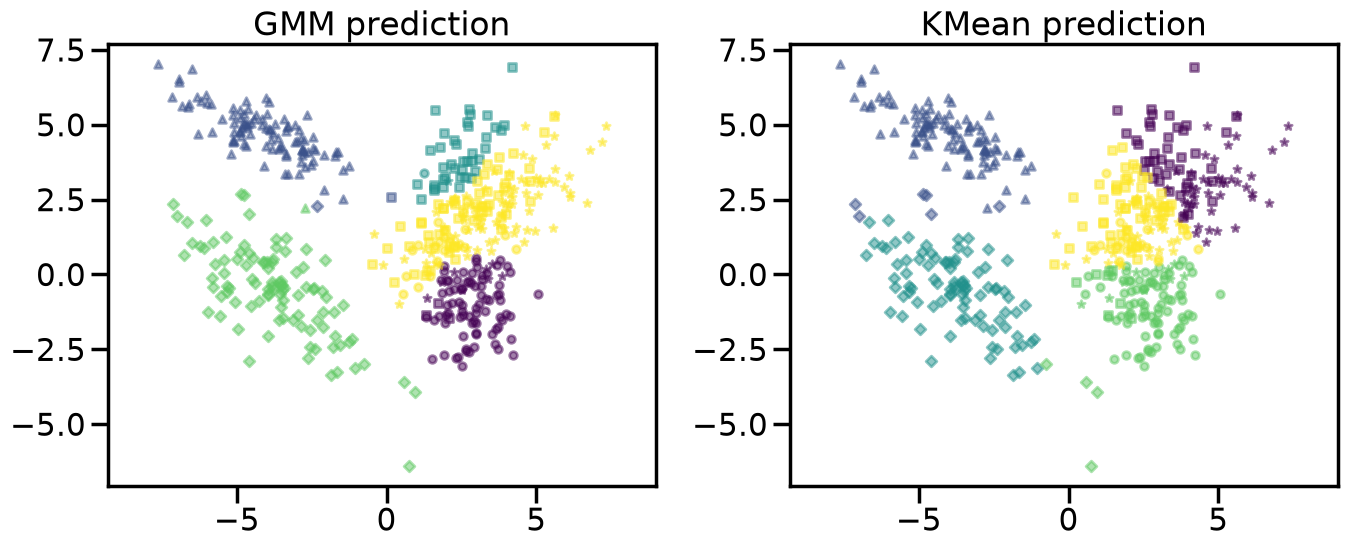

In [46]:
plot_predictions(X, y, my_labels, kmeans_labels, K)

**Comments**: The GMM doesn't recover well the clusters as they are superposed. It looks similar as K means.

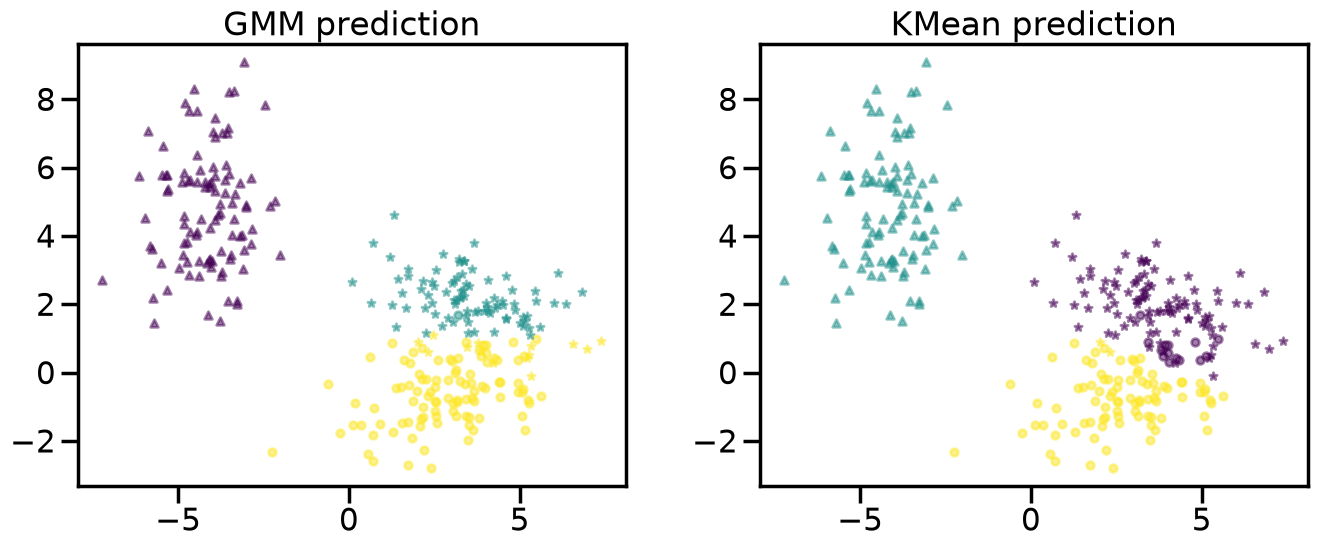

In [48]:
plot_predictions(X_easy, y_easy, my_gmm_easy.labels_, kmeans_easy_labels, 3)


We plot the iteration of the algorithm to see how points assignments moves during training

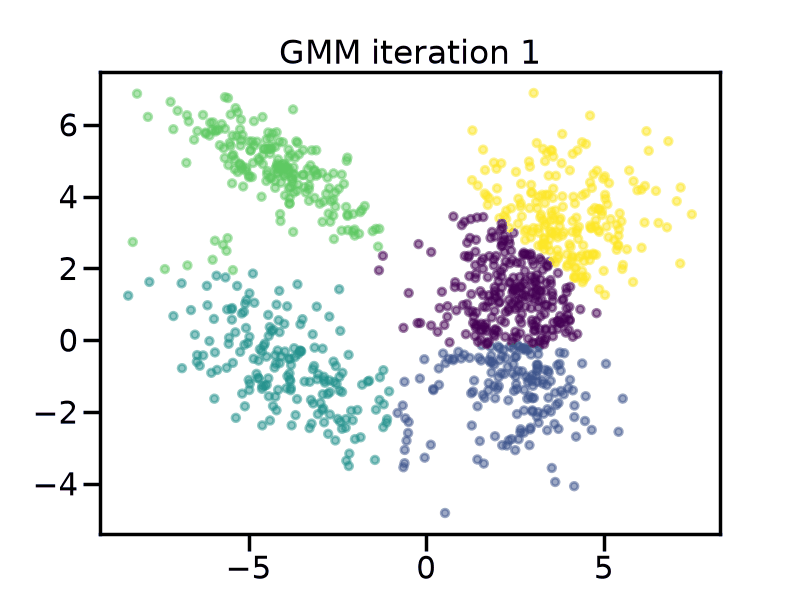

In [ ]:
from IPython.display import Image
Image(filename=my_gmm.generate_gif(X))

In [52]:
def log_likelihood(X, gmm):
    n, p = X.shape
    densities = np.zeros((n, gmm.k))
    for j in range(gmm.k):
        diff = X - gmm.mu_[j]
        inv = np.linalg.pinv(gmm.Sigma_[j])
        det = np.linalg.det(gmm.Sigma_[j])
        scale = (2 * np.pi) ** (-p / 2) / np.sqrt(det)
        densities[:, j] = gmm.alpha_[j] * scale * np.exp(-0.5 * np.einsum('np, pq, nq->n', diff, inv, diff))
    likelihood = np.sum(np.log(np.sum(densities, axis=1)))
    return likelihood

def BIC(X, gmm):
    n, p = X.shape
    k = gmm.k
    num_params = k - 1 + k * p + k * p * (p + 1) / 2  
    log_likelihood_value = log_likelihood(X, gmm)
    bic = -2 * log_likelihood_value + num_params * np.log(n)
    return bic

def AIC(X, gmm):
    n, p = X.shape
    k = gmm.k
    num_params = k - 1 + k * p + k * p * (p + 1) / 2  
    log_likelihood_value = log_likelihood(X, gmm)
    aic = -2 * log_likelihood_value + 2 * num_params
    return aic

In [53]:
aics = []
bics = []
labels_per_k = []
probs_label_per_k = []
for k in range(1, 10):
    gmm = my_GMM(k=k)
    gmm.fit(X)
    labels_per_k.append(gmm.labels_)
    probabilities = gmm.compute_proba(X)
    probs_label_per_k.append(probabilities)
    aics.append(AIC(X, gmm))
    bics.append(BIC(X, gmm))


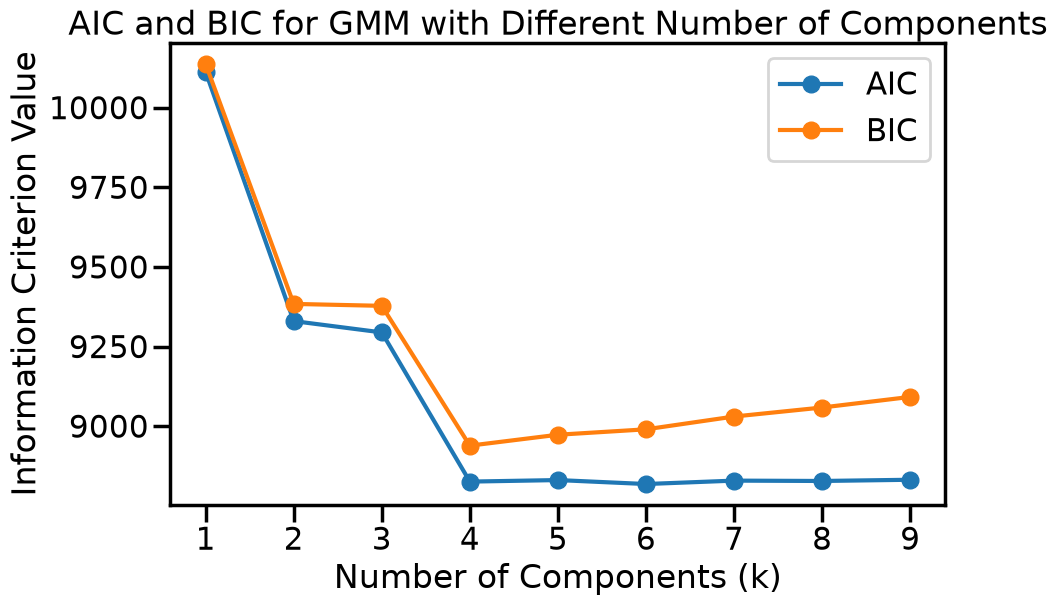

In [8]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, 10), aics, marker='o', label='AIC')
plt.plot(range(1, 10), bics, marker='o', label='BIC')
plt.xticks(range(1, 10))
plt.xlabel('Number of Components (k)')
plt.ylabel('Information Criterion Value')
plt.title('AIC and BIC for GMM with Different Number of Components')
plt.legend()

**Comments:** The model performs as good with 3 components that with only 2, because the GMM fails to recover the 3 clusters with K = 3. The value to keep is 4 as it corresponds to the lowest value with the "elbow" characteristic. We plot below the corresponding experiments to see how the points are assignated. 

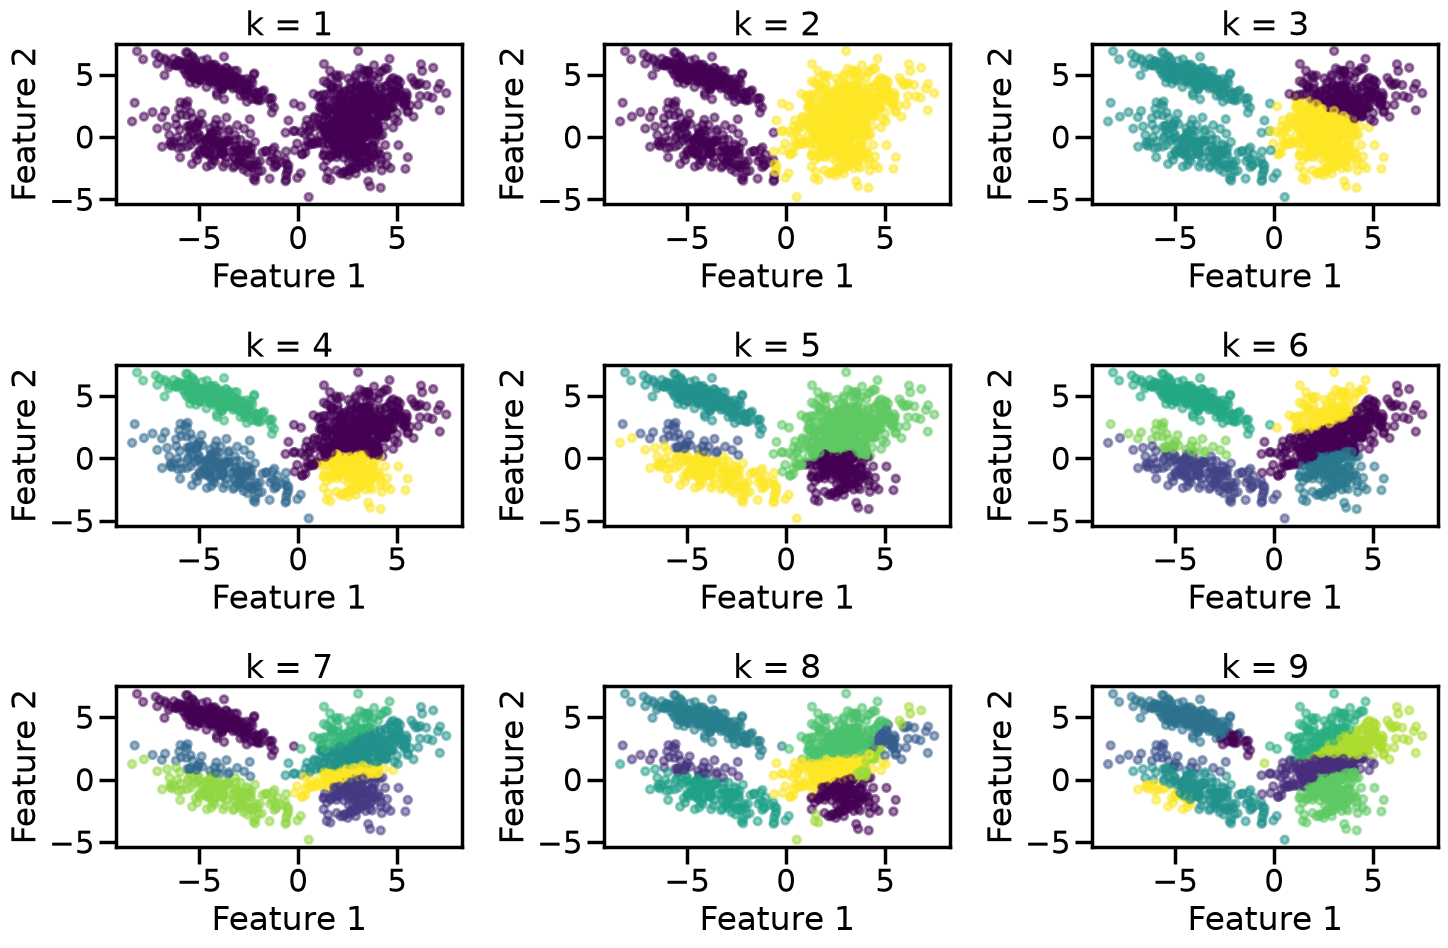

In [ ]:
def plot_distributions(X, labels_per_k):
    plt.figure(figsize=(15, 10))
    for k in range(1, 10):
        plt.subplot(3, 3, k)
        plt.scatter(X[:, 0], X[:, 1], c=labels_per_k[k-1], cmap='viridis', s=30, alpha=0.5)
        plt.title(f'k = {k}')
        plt.xlabel('Feature 1')
        plt.ylabel('Feature 2')
    plt.tight_layout()
    plt.show()
plot_distributions(X, labels_per_k)

**Comments:** Best value is here 4 as we described before. It is interesting to see that the GMM splits the right cluster before the two left clusters (top right figure), and to see that the original right cluster is recovered only at k=6. This highlights one drawback of GMM: when the clusters are superposed, it fails to identificate it (as we could have guessed).

## Cluster boundaries

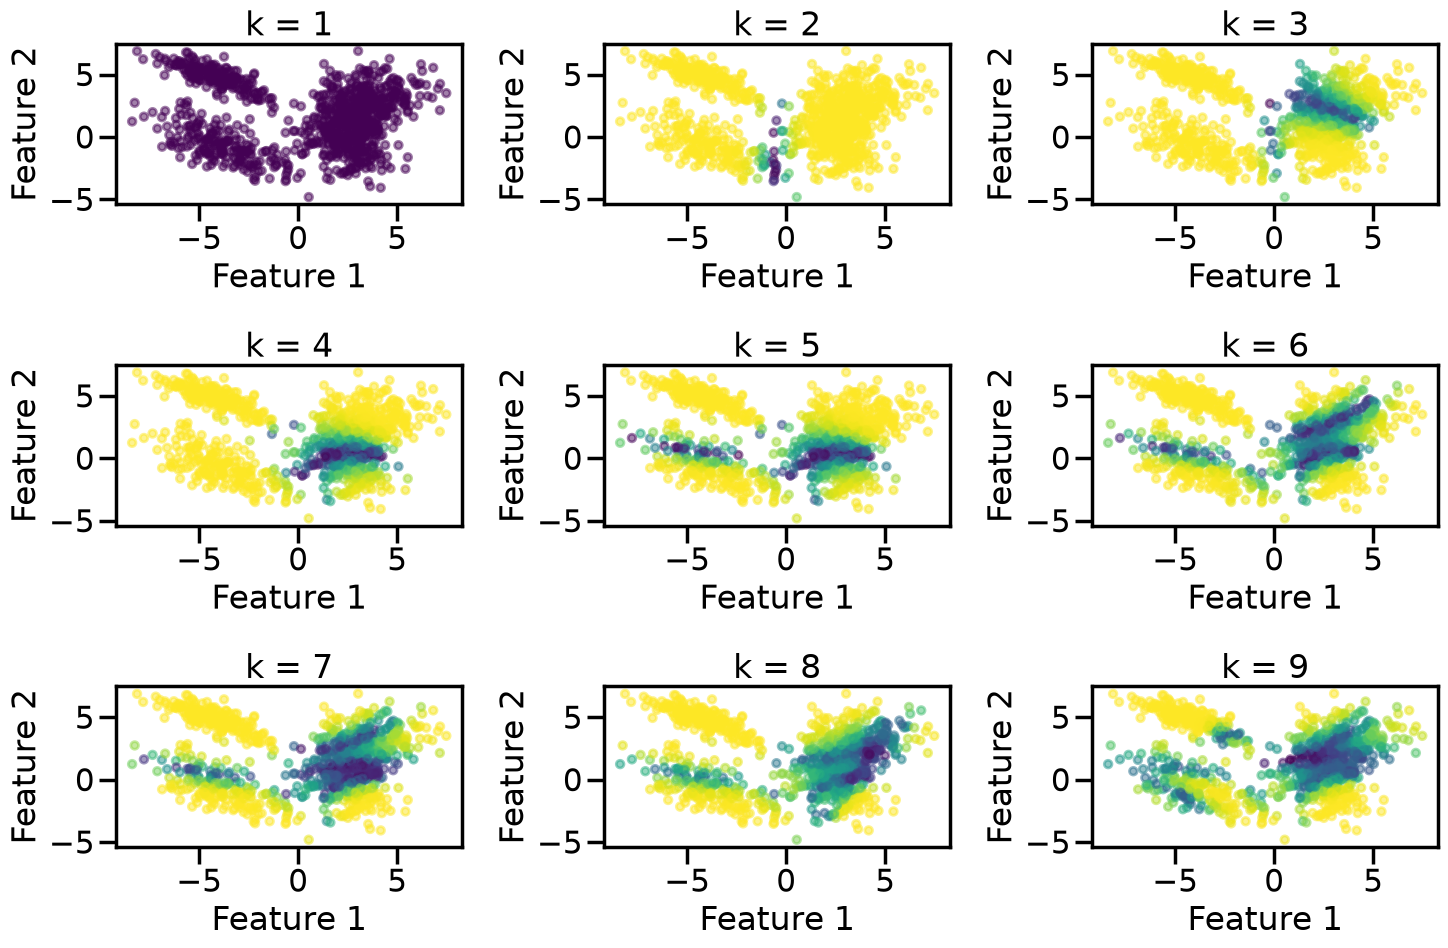

In [18]:
def plot_probabilities(X, probs_label_per_k):
    plt.figure(figsize=(15, 10))
    for k in range(1, 10):
        plt.subplot(3, 3, k)
        plt.scatter(X[:, 0], X[:, 1], c=np.max(probs_label_per_k[k-1], axis=1), cmap='viridis', s=30, alpha=0.5)
        plt.title(f'k = {k}')
        plt.xlabel('Feature 1')
        plt.ylabel('Feature 2')
    plt.tight_layout()
    plt.show()

plot_probabilities(X, probs_label_per_k)

**Comments:** We plot here the max probabilities for each individual points, regardless of their cluster assignment. If a point is between multiple clusters, all probabilities are far from 1 (at least lower 0.5 at the boundary between two clusters). This enables to highlight the uncertainties, and to keep only the yellow points as almost surely predicted, and the others as undetermined / noise.